In [28]:
import re
import os
import pandas as pd
import numpy as np
from Bio import SeqIO
from datetime import datetime
from plotnine import *
import geopandas as gpd

In [29]:
# Read in detections dataset 

all_detect_final = pd.read_csv("./metadata/detections_data/combinedNAm_detections_2021-2025.csv", sep = ',')

In [30]:
# Read in sequences dataset (HA)
ha_sequences = pd.read_csv("./metadata/sequence_metadata/NCBI-BVBRC_ha_detectionsgeodata.tsv", sep = '\t')

In [31]:
# Don't want any sequences that aren't from the main introduction because I will be using this for continuous phylogeography

ha_seqs_mainintro = ha_sequences.copy()

not_mainintro = ["A3", "A4", "A5", "A6", "D1.1", "D1.3"]
ha_seqs_mainintro = ha_seqs_mainintro.loc[~ha_seqs_mainintro["genoflu_genotype"].isin(not_mainintro)]

In [32]:
# Generate a year_month column in both

all_detect_final["year_month"] = all_detect_final["Collection Date"].str.split("-", expand = True)[0] + "_" + all_detect_final["Collection Date"].str.split("-", expand = True)[1]
ha_seqs_mainintro["year_month"] = ha_seqs_mainintro["year_only"].astype(str) + "_" + ha_seqs_mainintro["month_only"].astype(str).str.zfill(2)

In [33]:
# Make a dictionary with counts per year month

per_yearmonth = pd.DataFrame(all_detect_final["year_month"].value_counts()).rename({"year_month":"year_month", "count":"detections"}, axis = 1)
per_yearmonth["sequences"] = ha_seqs_mainintro["year_month"].value_counts()

In [34]:
print(per_yearmonth)
per_yearmonth_2021_2024 = per_yearmonth.loc[~per_yearmonth.index.astype(str).str.contains("2025", regex = False)]
print(per_yearmonth_2021_2024)

            detections  sequences
year_month                       
2024_12           1310       10.0
2022_09           1253      548.0
2022_04           1105      862.0
2022_11           1098      380.0
2023_11           1026      118.0
2022_10            904      275.0
2025_02            818        NaN
2025_01            813        3.0
2022_05            797      641.0
2025_09            752        NaN
2024_11            733        4.0
2022_12            717      293.0
2023_10            716       66.0
2025_11            690        NaN
2023_12            605       55.0
2025_10            584        NaN
2022_03            527      411.0
2022_08            490      262.0
2023_01            419      194.0
2022_06            416      331.0
2024_01            393       52.0
2025_03            318        NaN
2024_02            310      124.0
2024_10            281        3.0
2022_01            253      110.0
2022_07            239      181.0
2022_02            220      124.0
2023_02       

In [35]:
# Calculate ratio of sequences to detections

per_yearmonth_2021_2024_upt = per_yearmonth_2021_2024.copy()

# per_yearmonth["ratio"] = per_yearmonth["sequences"] / per_yearmonth["detections"]
per_yearmonth_2021_2024_upt["ratio"] = per_yearmonth_2021_2024_upt["sequences"] / per_yearmonth_2021_2024_upt["detections"]

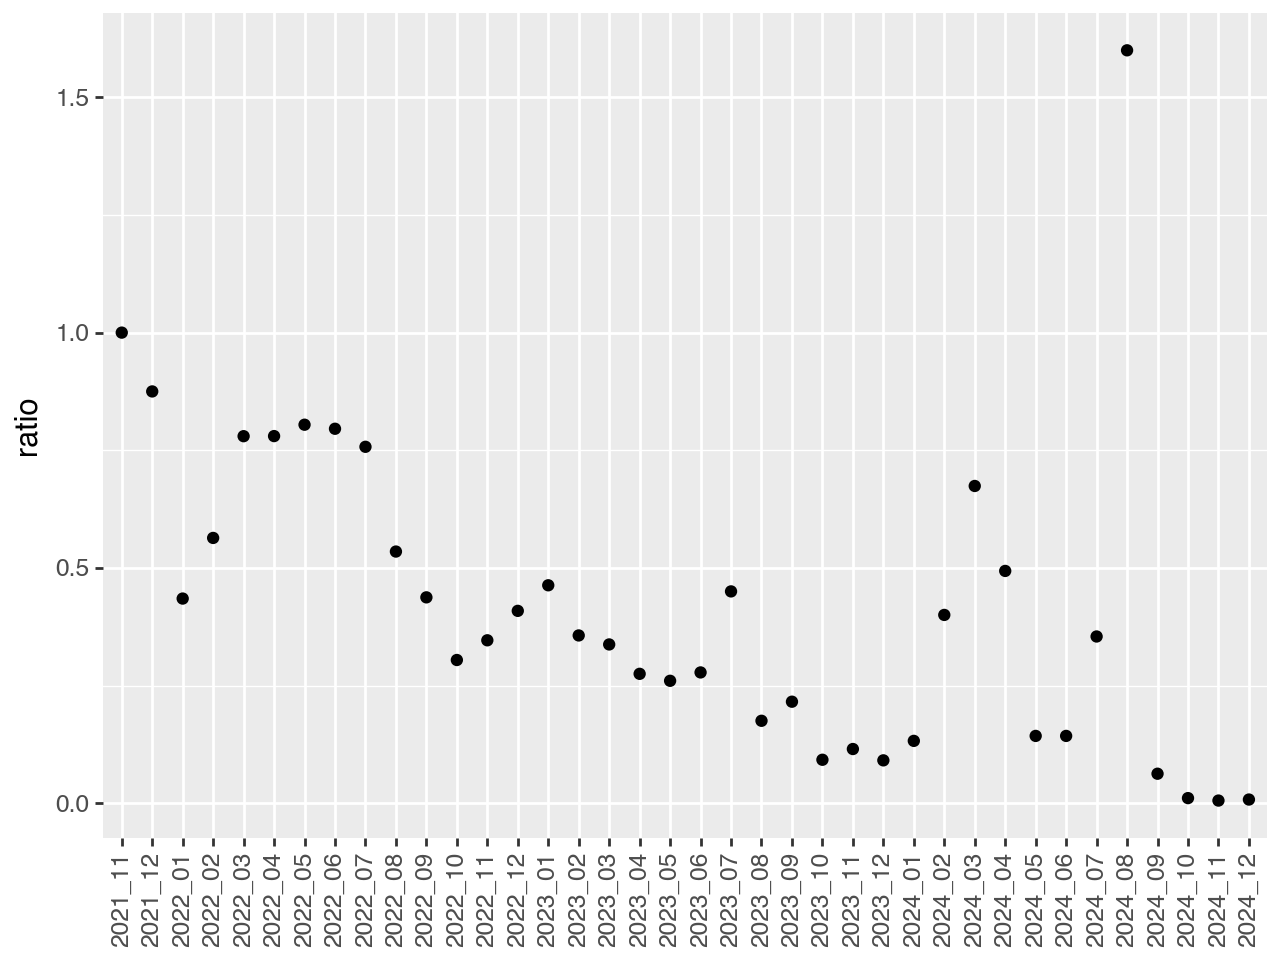

In [36]:
(
    ggplot(per_yearmonth_2021_2024_upt, aes(x = per_yearmonth_2021_2024_upt.index, y = "ratio"))
    + geom_point()
    + theme(axis_text_x=element_text(rotation=90))
)

In [37]:
# Calculate the percentage of detections per year_month

# total_detect = per_yearmonth["detections"].sum()
total_detect = per_yearmonth_2021_2024_upt["detections"].sum()
print(total_detect)
#per_yearmonth["pct_detect"] = per_yearmonth["detections"] / total_detect
per_yearmonth_2021_2024_upt["pct_detect"] = per_yearmonth_2021_2024_upt["detections"] / total_detect
print(per_yearmonth_2021_2024_upt["pct_detect"].sum()) # This should add up to ~1, its just a check

14998
1.0


In [38]:
# Cacluate the smallest ratio of sequences per detections

# smallest_ratio = per_yearmonth[per_yearmonth["ratio"].eq(per_yearmonth["ratio"].min())]
# print(smallest_ratio)

smallest_ratio_2021_2024 = per_yearmonth_2021_2024_upt[per_yearmonth_2021_2024_upt["ratio"].eq(per_yearmonth_2021_2024_upt["ratio"].min())]
print(smallest_ratio_2021_2024)

# Calculate the smallest ratio amongst sequences from Fall 2023
# min_fall_2023 = per_yearmonth_2021_2024_upt["ratio"].min(per_yearmonth_2021_2024_upt.loc[per_yearmonth_2021_2024_upt.index.astype(str).str.contains("2023", regex = False)])
min_fall_2023 = per_yearmonth_2021_2024_upt.loc[per_yearmonth_2021_2024_upt.index.astype(str).str.contains("2023"), "ratio"].min()
print(min_fall_2023)
smallest_ratio_fall2023 = per_yearmonth_2021_2024_upt[per_yearmonth_2021_2024_upt["ratio"].eq(min_fall_2023)]
print(smallest_ratio_fall2023)

            detections  sequences     ratio  pct_detect
year_month                                             
2024_11            733        4.0  0.005457    0.048873
0.09090909090909091
            detections  sequences     ratio  pct_detect
year_month                                             
2023_12            605       55.0  0.090909    0.040339


In [39]:
# If you only have X sequences from that year-month, and that is P percent of the total, what is the total

#limiting_sequences = float(smallest_ratio["sequences"].iloc[0]) # limiting sequences is the number of sequences where there is the biggest difference between seq and detect
limiting_sequences = float(smallest_ratio_2021_2024["sequences"].iloc[0])
#limiting_pct = float(smallest_ratio["pct_detect"].iloc[0]) # limiting percentage is the percent of detections where there is the biggest difference between seq and detect
limiting_pct = float(smallest_ratio_2021_2024["pct_detect"].iloc[0])
avail_seq = limiting_sequences / limiting_pct
print(avail_seq)

81.84447476125511


In [40]:
# If I use the minimum ratio from Fall 2023 as the limiting month, how many sequences can I use

limit_seq_fall2023 = float(smallest_ratio_fall2023["sequences"].iloc[0])
limit_pct_fall2023 = float(smallest_ratio_fall2023["pct_detect"].iloc[0])
avail_seq_fall2023 = limit_seq_fall2023 / limit_pct_fall2023
print(avail_seq_fall2023)

1363.4545454545455


In [41]:
# Use the above to determine the total number of sequences you can use

# per_yearmonth["seq_to_use_raw"] = per_yearmonth["pct_detect"] * avail_seq
# print(per_yearmonth["seq_to_use_raw"].sum())

per_yearmonth_2021_2024_upt["seq_to_use_raw"] = per_yearmonth_2021_2024_upt["pct_detect"] * avail_seq_fall2023
print(per_yearmonth_2021_2024_upt["seq_to_use_raw"].sum())

1363.4545454545457


In [42]:
# Round the sequence number to use to the nearest whole number

#per_yearmonth["seq_to_use"] = np.floor(per_yearmonth["seq_to_use_raw"])
per_yearmonth_2021_2024_upt["seq_to_use"] = np.floor(per_yearmonth_2021_2024_upt["seq_to_use_raw"])

# If you're supposed to use 0.0 sequences (rounded), use 1
#per_yearmonth.loc[per_yearmonth["seq_to_use"] == 0.0, "seq_to_use"] = 1
per_yearmonth_2021_2024_upt.loc[per_yearmonth_2021_2024_upt["seq_to_use"] == 0.0, "seq_to_use"] = 1

print(per_yearmonth_2021_2024_upt["seq_to_use"].sum())

1349.0


In [43]:
# Same calulations as above, just with the limiting sequences from Fall 2023

fall2023_test = per_yearmonth_2021_2024_upt.copy()

fall2023_test["seq_to_use_raw"] = fall2023_test["pct_detect"] * avail_seq_fall2023
fall2023_test["seq_to_use"] = np.floor(fall2023_test["seq_to_use_raw"])
fall2023_test.loc[fall2023_test["seq_to_use"] == 0.0, "seq_to_use"] = 1
print(fall2023_test["seq_to_use"].sum())

1349.0


In [44]:
# per_yearmonth_dict = per_yearmonth.to_dict(orient = "index")
# print(per_yearmonth_dict)

per_yearmonth_dict = fall2023_test.to_dict(orient = "index")
print(per_yearmonth_dict)

{'2024_12': {'detections': 1310, 'sequences': 10.0, 'ratio': 0.007633587786259542, 'pct_detect': 0.08734497933057742, 'seq_to_use_raw': 119.09090909090911, 'seq_to_use': 119.0}, '2022_09': {'detections': 1253, 'sequences': 548.0, 'ratio': 0.43735035913806863, 'pct_detect': 0.08354447259634618, 'seq_to_use_raw': 113.9090909090909, 'seq_to_use': 113.0}, '2022_04': {'detections': 1105, 'sequences': 862.0, 'ratio': 0.7800904977375566, 'pct_detect': 0.07367649019869316, 'seq_to_use_raw': 100.45454545454545, 'seq_to_use': 100.0}, '2022_11': {'detections': 1098, 'sequences': 380.0, 'ratio': 0.3460837887067395, 'pct_detect': 0.07320976130150687, 'seq_to_use_raw': 99.81818181818183, 'seq_to_use': 99.0}, '2023_11': {'detections': 1026, 'sequences': 118.0, 'ratio': 0.11500974658869395, 'pct_detect': 0.06840912121616216, 'seq_to_use_raw': 93.27272727272728, 'seq_to_use': 93.0}, '2022_10': {'detections': 904, 'sequences': 275.0, 'ratio': 0.30420353982300885, 'pct_detect': 0.060274703293772505, 'seq

In [45]:
# compare_df = per_yearmonth_2021_2024_upt
compare_df = fall2023_test

In [46]:
compare_df = compare_df.reset_index()

In [47]:
month_order = ["2021_11","2021_12", "2022_01", "2022_02", "2022_03", "2022_04", "2022_05", "2022_06",
               "2022_07", "2022_08", "2022_09", "2022_10", "2022_11", "2022_12","2023_01", "2023_02", "2023_03", "2023_04", 
               "2023_05", "2023_06", "2023_07", "2023_08", "2023_09", "2023_10", "2023_11", "2023_12", "2024_01", "2024_02", 
               "2024_03", "2024_04", "2024_05", "2024_06","2024_07", "2024_08", "2024_09", "2024_10", "2024_11", "2024_12"]

compare_df["year_month"] = pd.Categorical(compare_df["year_month"], categories=month_order, ordered=True)

In [24]:
compare_df.head()

,year_month,detections,sequences,ratio,pct_detect,seq_to_use_raw,seq_to_use
0,2024_12,1310,10.0,0.007634,0.087345,119.090909,119.0
1,2022_09,1253,548.0,0.437350,0.083544,113.909091,113.0
2,2022_04,1105,862.0,0.780090,0.073676,100.454545,100.0
3,2022_11,1098,380.0,0.346084,0.073210,99.818182,99.0
4,2023_11,1026,118.0,0.115010,0.068409,93.272727,93.0


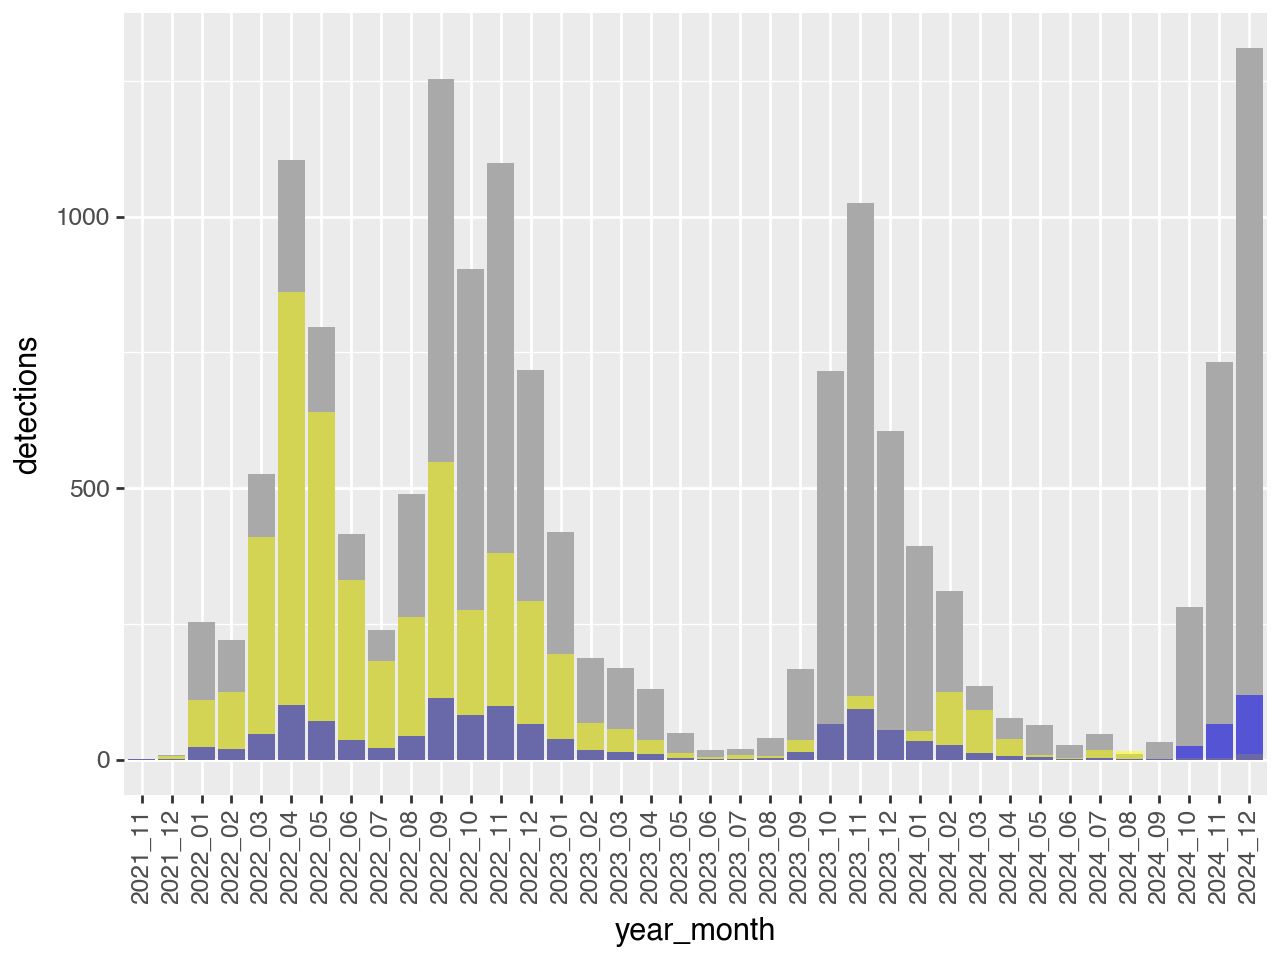

In [21]:
plot = (
    ggplot(compare_df, aes(x = "year_month"))
    # + geom_bar(aes(y = "detections"), stat = "identity", fill = "blue")
    # + geom_bar(aes(y = "sequences"), stat = "identity", fill = "green")
    # + geom_bar(aes(y = "seq_to_use"), stat = "identity", fill = "red")
    + geom_bar(aes(y = "detections"), stat = "identity", fill = "darkgrey", alpha = 1)
    + geom_bar(aes(y = "sequences"), stat = "identity", fill = "yellow", alpha = 0.5)
    + geom_bar(aes(y = "seq_to_use"), stat = "identity", fill = "blue", alpha = 0.5)
    + theme(axis_text_x=element_text(rotation=90))
)

plot.show()

In [22]:
# Group detections by year_month and then count host_group per year_month

year_month_host = pd.DataFrame(all_detect_final.groupby("year_month")["Host_Broad"].value_counts())

In [23]:
year_month_host = year_month_host.reset_index() # reset index so you can use it to calculate

In [24]:
# What proportion of each year_month is seen in each host (detections)

for idx, row in year_month_host.iterrows():
    
    time = row["year_month"]
    host = row["Host_Broad"]
    count = row["count"]

    total = len(all_detect_final.loc[all_detect_final["year_month"] == time])
    year_month_host.at[idx, "percent_host_per_yrmon"] = count / total

In [25]:
# Turn this dataframe into a dictionary with the count and percent of this host per year_month detecctions for each year_month and host

host_per_yrmon_dict = {}

for idx, row in year_month_host.iterrows():
    ym = row["year_month"]
    host = row["Host_Broad"]
    count = row["count"]
    percent = row["percent_host_per_yrmon"]

    if ym not in host_per_yrmon_dict:
        host_per_yrmon_dict[ym] = {}
    
    host_per_yrmon_dict[ym][host] = {
        "count": count,
        "percent_host_per_yrmon": percent
    }

In [26]:
seqperhost_dict = {}

for key in host_per_yrmon_dict: # hoat_per_yrmon_dict counts the number of detections per host per yearmonth 
    yrmon = key
    # print(key)
    
    host_dict = host_per_yrmon_dict[key]
    # print(host_dict)

    hosts = list(host_dict)
    # print(hosts)

    seqperhost_dict[key] = {}

    for i in hosts:
        host_name = i
        if yrmon in per_yearmonth_dict:
            pct_detect_per_host = host_dict[i]["percent_host_per_yrmon"]
            seq_per_yrmon = per_yearmonth_dict[yrmon]["seq_to_use"]
            seq_per_host_raw = pct_detect_per_host * seq_per_yrmon
            # print(i, seq_per_yrmon, seq_per_host_raw)
        else:
            seq_per_yrmon = 0
            seq_per_host_raw = 0

        seqperhost_dict[key].update({host_name:{"yrmon_seq": seq_per_yrmon, "yrmon_host_seq_raw": seq_per_host_raw}}) # Replacing numbers with same per location

In [27]:
# print(seqperhost_dict)

In [28]:
def create_minidict(seqperhost_dict, key):
    mini_dict = {key:{}}

    yrmon = key
    for host in seqperhost_dict[key]:
        seq_per_yrmon_rounded = round(seqperhost_dict[key][host_name]["yrmon_host_seq_raw"])
        # print(seq_per_yrmon_rounded)
        if seq_per_yrmon_rounded > 0:
            # print(host, "yes", seqperhost_dict[key][location]['yrmon_loc_seq_rounded'])
            pass
        else:
            # print(host, "no")
            mini_dict[key].update({host:seqperhost_dict[key][host]['yrmon_host_seq_raw']})
    
    return(mini_dict)

In [29]:
mini_dict = create_minidict(seqperhost_dict, "2022_01")
print(mini_dict)

{'2022_01': {'duck': 22.09090909090909, 'shorebird': 0.3636363636363636, 'bird-of-prey': 0.2727272727272727, 'goose-swan': 0.1818181818181818, 'songbird-etc': 0.0909090909090909}}


In [30]:
# testy_dict[key].update({location_name:{"yrmon_seq": seq_per_yrmon, "yrmon_loc_seq": seq_per_loc_raw}}) # Replacing numbers with same per location

for key in seqperhost_dict:
    if key in per_yearmonth_dict:
        no_hosts = len(seqperhost_dict[key])
        sum_seq = per_yearmonth_dict[key]["seq_to_use"]
    
        for host_name in seqperhost_dict[key]:
            
            seq_per_yrmon = seqperhost_dict[key][host_name]["yrmon_seq"]
            seq_per_yrmon_raw = seqperhost_dict[key][host_name]["yrmon_host_seq_raw"]
            # print(seq_per_yrmon, seq_per_yrmon_raw)
            
            seq_per_yrmon_rounded = round(seqperhost_dict[key][host_name]["yrmon_host_seq_raw"])
            seqperhost_dict[key][host_name]["yrmon_hostc_seq_rounded"] = seq_per_yrmon_rounded
    
            # If there is only 1 sequences in that month
            if seq_per_yrmon == 1: 
                
                # If there is 1 sequence per month and one location
                if no_hosts == 1: 
                    seqperhost_dict[key][host_name]["yrmon_host_seq_final"] = 1 # Take the sequence from that location
                
                # If there is 1 sequence per month but more locations
                elif no_hosts > 1: 
                    # only_loc = max(seqperloc_dict[key][location_name]["yrmon_loc_seq_raw"], key = lambda k:testy_dict[key][location_name]) # My version
                    only_host = max(seqperhost_dict[key], key=lambda host: seqperhost_dict[key][host]["yrmon_host_seq_raw"]) #Chat GPT's version
                    if host_name == only_host: 
                        seqperhost_dict[key][host_name]["yrmon_host_seq_final"] = 1 # Take the sequence from this location
                    else:
                        seqperhost_dict[key][host_name]["yrmon_host_seq_final"] = 0
    
                else: 
                    print("something odd that I didn't expect is happening!")
    
            # If there is more than one sequence per month, there may be issues with multiple locations with 0 final seqs
            elif seq_per_yrmon > 1: # and no_host > seq_per_yrmon: 
                if seq_per_yrmon_rounded > 0:
                    seqperhost_dict[key][host_name]["yrmon_host_seq_final"] = seq_per_yrmon_rounded
                    #pass
                elif seq_per_yrmon_rounded == 0: # for the collection of locations where seq_per_yrmon_rounded is 0
                    mini_dict = create_minidict(seqperhost_dict, key)
                    # print(mini_dict)
                    only_host = max(mini_dict[key], key=lambda host: mini_dict[key][host])
                    # print(key, only_loc)
                    if host_name == only_host: 
                        seqperhost_dict[key][host_name]["yrmon_host_seq_final"] = 1 # Take the sequence from this location
                    else:
                        seqperhost_dict[key][host_name]["yrmon_host_seq_final"] = 0

    else: # If there are no sequences from that yrmon
        # print(seqperloc_dict[key])
        for host_name in seqperhost_dict[key]:
            # print(key, location_name)
            seqperhost_dict[key][host_name]["yrmon_host_seq_rounded"] = 0
            seqperhost_dict[key][host_name]["yrmon_host_seq_final"] = 0

In [31]:
print(seqperhost_dict["2023_12"])

{'duck': {'yrmon_seq': 55.0, 'yrmon_host_seq_raw': 31.454545454545457, 'yrmon_hostc_seq_rounded': 31, 'yrmon_host_seq_final': 31}, 'goose-swan': {'yrmon_seq': 55.0, 'yrmon_host_seq_raw': 14.727272727272728, 'yrmon_hostc_seq_rounded': 15, 'yrmon_host_seq_final': 15}, 'bird-of-prey': {'yrmon_seq': 55.0, 'yrmon_host_seq_raw': 5.818181818181818, 'yrmon_hostc_seq_rounded': 6, 'yrmon_host_seq_final': 6}, 'shorebird': {'yrmon_seq': 55.0, 'yrmon_host_seq_raw': 1.4545454545454546, 'yrmon_hostc_seq_rounded': 1, 'yrmon_host_seq_final': 1}, 'songbird-etc': {'yrmon_seq': 55.0, 'yrmon_host_seq_raw': 1.1818181818181819, 'yrmon_hostc_seq_rounded': 1, 'yrmon_host_seq_final': 1}, 'ground-bird': {'yrmon_seq': 55.0, 'yrmon_host_seq_raw': 0.27272727272727276, 'yrmon_hostc_seq_rounded': 0, 'yrmon_host_seq_final': 0}, 'diving-bird': {'yrmon_seq': 55.0, 'yrmon_host_seq_raw': 0.09090909090909091, 'yrmon_hostc_seq_rounded': 0, 'yrmon_host_seq_final': 0}}


In [32]:
# Now make a new metadata file with the proportional number of samples

In [33]:
def proportional_sampling(df, dictionary):
    
    grouped = df.groupby(["year_month", "ncbibvbrc_hostgroup"]) # Group the sequences by month and division

    proportional = [] # Initialize a new list

    for (yr_mon, host), group in grouped:
        if host in dictionary[yr_mon]: # If the location is in the dictionary
            # print(yr_mon, location, "yes") #, dictionary[yr_mon][location])
            goal_number = dictionary[yr_mon][host]["yrmon_host_seq_final"] # Set a goal number
        elif host not in dictionary[yr_mon]:
            # print(yr_mon, location, "no")
            goal_number = 0
        else:
            print(f"something unexpected happened at {yr_mon, host}")

    #     # if len(group) < number:
    #     #     print(yr_mon, location, number, len(group))

        # Sometimes there are fewer sequences from that location than I want, so just take all the sequences from that location that I can
        # print(yr_mon, location, goal_number, len(group))
        n_to_sample = min(goal_number, len(group))  

        proportional.append(group.sample(n_to_sample, replace = False))

    proportional_df = pd.concat(proportional)

    return(proportional_df)

In [34]:
proportional_seqs = proportional_sampling(ha_seqs_mainintro, seqperhost_dict)

In [35]:
print(len(proportional_seqs))

1014


In [37]:
print(len(ha_seqs_mainintro.loc[ha_seqs_mainintro["year_month"] == "2023_12"]))
print(len(proportional_seqs.loc[proportional_seqs["year_month"] == "2023_12"]))

55
31


In [39]:
proportional_seqs.to_csv("./BEAST/empirical_trees/submission_files/2026-02-04_main-intro_prop-time-host_ha_empirical_targetedbeast/inputs/prop_time-host_metadata.tsv", 
                         sep = "\t")

In [40]:
# Then pull these samples from the big FASTA file

In [49]:
#Function: Read in the FASTA as a dataframe

def fasta_reader(path_to_fasta, output_name):
    fasta_data = []
    FASTANAME = path_to_fasta
        
    with open(FASTANAME) as f:
        header = ""
        sequence = ""
        for line in f:
            if line.startswith(">"):
                if header != "":
                    fasta_data.append({"header": header, "sequence": sequence})
                header = line.strip() 
                sequence = ""
            else:
                sequence += line.strip()
        fasta_data.append({"header": header, "sequence": sequence}) #last line 
        
    globals()[output_name] = pd.DataFrame(fasta_data)

    return

In [42]:
# Function to write a new fasta with just the sequences in the metadata
# Adapted from Maria

def fasta_writer(path, filename, df):
            
    try:  
        os.mkdir(path)

    except OSError as error:
        pass

    with open(f"{path}{filename}", "w") as f:
        for index, row in df.iterrows():
            f.write(f"{row['header']}\n")
            f.write(f"{row['sequence']}\n")

In [43]:
# Function: remove the carrot from the header

def header_to_strain(df):
    df["strain"] = df["header"].str.replace(">","")

    return(df)

In [44]:
# Function: parse to include

def parse_toinclude(objects_list, file_to_parse):
    # Define the list as the objects to include
    to_include = objects_list

    # Filter rows where the 'taxon' value is in the strains_set
    parsed = file_to_parse[file_to_parse["strain"].isin(to_include)]

    return parsed

In [45]:
# List the strain names

list_of_strains = proportional_seqs["strain"].to_list()

fasta_reader("./raw_data/ncbi-bvbrc_from-meta_ha.fasta", "ha_fasta")

ha_fasta_strain = header_to_strain(ha_fasta)

parsed_fasta = parse_toinclude(list_of_strains, ha_fasta_strain)

In [46]:
print(len(parsed_fasta))

1014


In [47]:
fasta_writer("./BEAST/empirical_trees/submission_files/2026-02-04_main-intro_prop-time-host_ha_empirical_targetedbeast/inputs/", "prop_time-host_metadata.fasta", parsed_fasta)

In [ ]:
# Make an alignment on MAFFT

In [58]:
# Below, I want to plot the FASTA strains over time with the detections over time
# I am picking on FASTA strains rather than metadata because I removed a number of FASTA strains for having no sequence or no location data
# So the final FASTA is actually more up-to-date than the metadata

In [55]:
fasta_reader("./BEAST/empirical_trees/submission_files/2026-04-22_main-intro_prop-time-host_ha_empirical_targetedbeast_noLP/inputs/prop_time-host_aligned.fasta", "proptimehost_fasta")
print(len(proptimehost_fasta))
# print(proptimehost_fasta["header"].str.split("|", expand = True)[1].str.split("-", expand = True)[0])
proptimehost_fasta["year_month"]= proptimehost_fasta["header"].str.split("|", expand = True)[1].str.split("-", expand = True)[0] + "_" + proptimehost_fasta["header"].str.split("|", expand = True)[1].str.split("-", expand = True)[1]

957


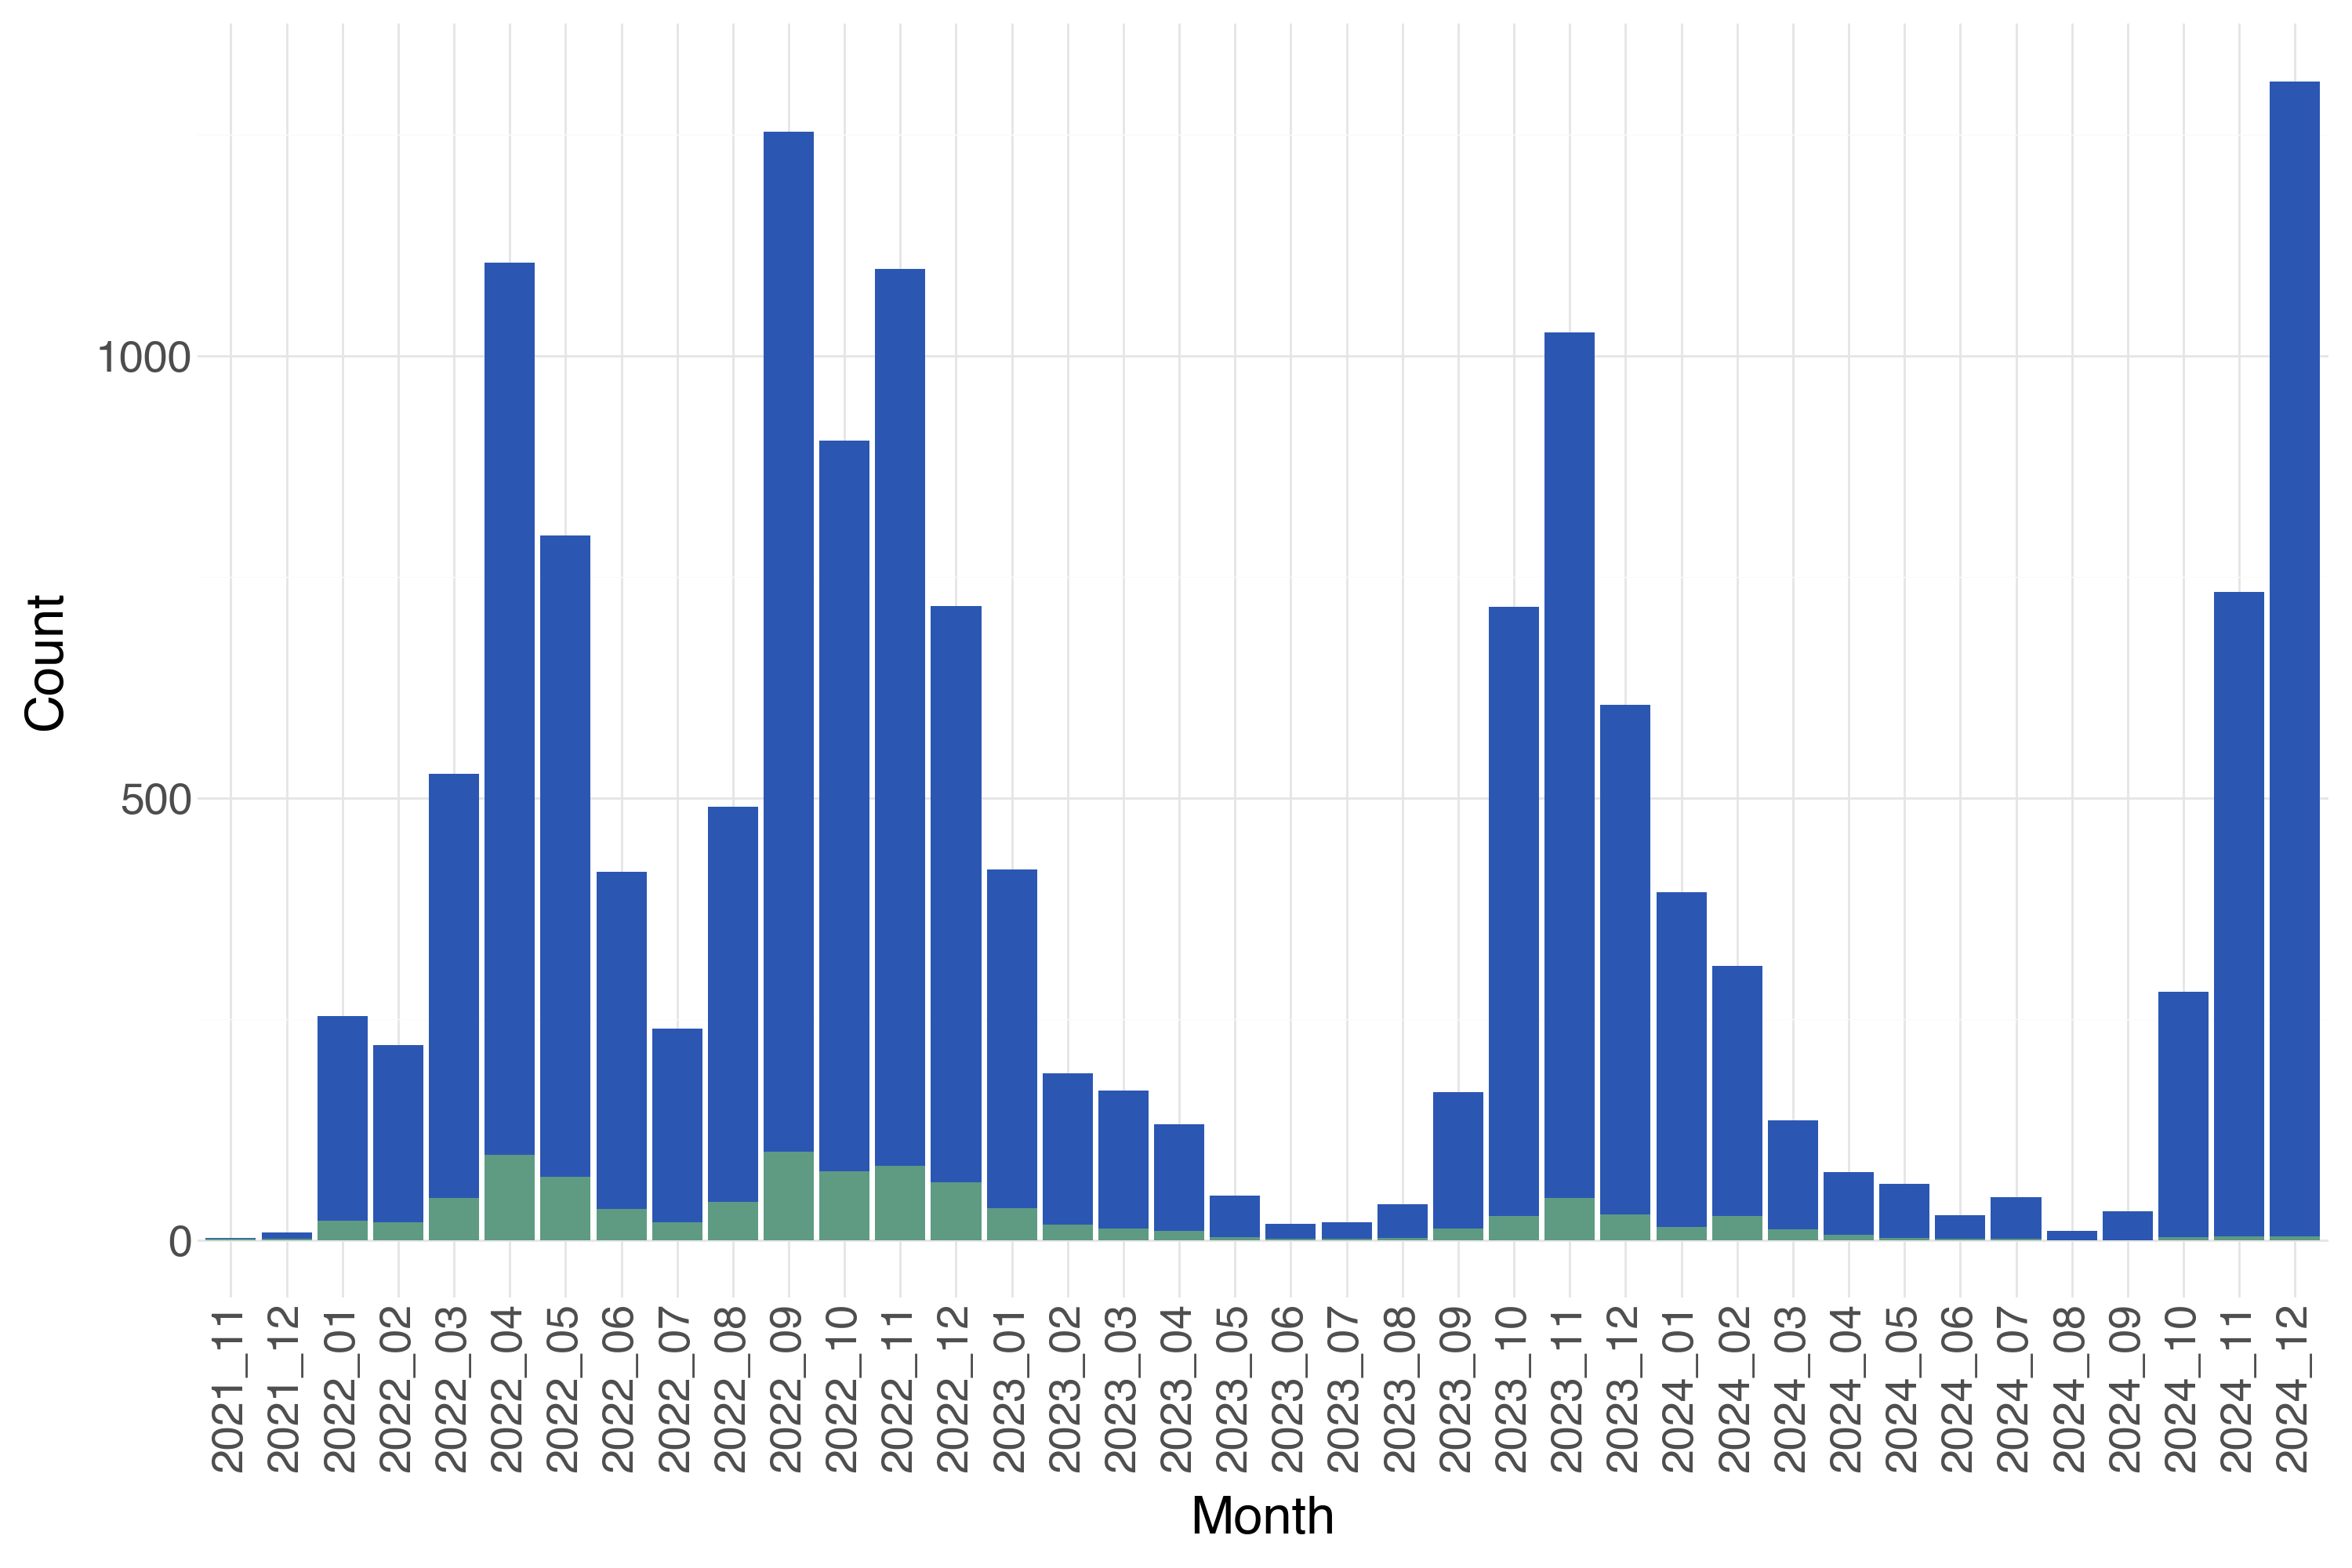

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 10 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./metadata/exploratory_data_analysis/prop-time-host.png


In [57]:
plot2 = (
    ggplot()
    + geom_bar(data = compare_df, mapping= aes(x = "year_month", y = "detections"), stat = "identity", fill = "#2B57B3")
    + geom_bar(data = proptimehost_fasta, mapping = aes(x = "year_month"), stat = "count", fill = "#5E9B82")
    + labs(x = "Month", y = "Count")
    + theme_minimal()
    + theme(figure_size = (15,10), axis_title_x = element_text(size = 24), axis_title_y = element_text(size = 24), text=element_text(size=20), axis_text_x = element_text(rotation = 90))
)

plot2.show()
plot2.save(filename = "./metadata/exploratory_data_analysis/prop-time-host.png", height=10, width=15, units = 'in', dpi=750)